<a href="https://colab.research.google.com/github/pratyay2409/NLP/blob/Assignment/NLP_Activity_4_Problem_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab Activity-4**

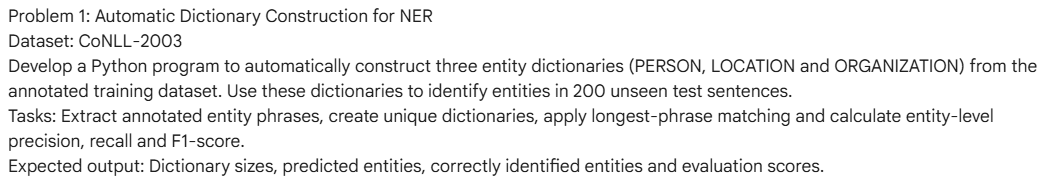

### Problem 1:

In [11]:
!pip install -q datasets

from collections import defaultdict
from datasets import load_dataset, utils

utils.logging.disable_progress_bar()

In [17]:
# CoNLL-2003 tag mapping:
# 1: B-PER, 2: I-PER, 3: B-ORG, 4: I-ORG, 5: B-LOC, 6: I-LOC
TAG_MAP = {
    1: ("B", "PER"), 2: ("I", "PER"),
    3: ("B", "ORG"), 4: ("I", "ORG"),
    5: ("B", "LOC"), 6: ("I", "LOC")
}
TARGET_TYPES = {"PER", "LOC", "ORG"}

print("Downloading and loading CoNLL-2003 dataset...")
# Load the dataset using the official ID (which now defaults to safe Parquet)
dataset = load_dataset("BramVanroy/conll2003")
train_data = dataset["train"]
test_data = dataset["test"].select(range(200))
print(f"Loaded {len(train_data)} training samples and {len(test_data)} test sentences.")

Loaded 14041 training samples and 200 test sentences.


In [18]:
# Defines a helper function to parse consecutive tokens using BIO prefix rules to extract complete multi-word entity spans with their start and end index positions.
def extract_gold_entities(tokens, ner_tags):
    """
    Extracts entities as: (start_token_idx, end_token_idx, entity_text, entity_type)
    using BIO boundary decoding.
    """
    entities = []
    current_tokens = []
    current_type = None
    start_idx = 0

    for idx, (token, tag_id) in enumerate(zip(tokens, ner_tags)):
        prefix, ent_type = TAG_MAP.get(tag_id, ("O", None))

        if prefix == "B":
            if current_type and current_type in TARGET_TYPES:
                entities.append((start_idx, idx, " ".join(current_tokens), current_type))
            current_tokens = [token]
            current_type = ent_type
            start_idx = idx
        elif prefix == "I" and current_type == ent_type:
            current_tokens.append(token)
        else:
            if current_type and current_type in TARGET_TYPES:
                entities.append((start_idx, idx, " ".join(current_tokens), current_type))
            current_tokens = []
            current_type = None

    if current_type and current_type in TARGET_TYPES:
        entities.append((start_idx, len(tokens), " ".join(current_tokens), current_type))

    return entities

In [19]:
# Extracts all entity phrases from the training set, resolves multi-class conflicts by majority vote, builds unique dictionaries for PER, LOC, and ORG, and outputs their sizes.

type_counts = defaultdict(lambda: defaultdict(int))

for sample in train_data:
    entities = extract_gold_entities(sample["tokens"], sample["ner_tags"])
    for _, _, text, ent_type in entities:
        token_tuple = tuple(text.lower().split())
        type_counts[token_tuple][ent_type] += 1

dictionaries = {t: set() for t in TARGET_TYPES}
for token_tuple, counts in type_counts.items():
    best_type = max(counts, key=counts.get)
    dictionaries[best_type].add(token_tuple)

max_phrase_len = max((len(t) for d in dictionaries.values() for t in d), default=1)

print("=== 1. Dictionary Sizes ===")
for ent_type in sorted(TARGET_TYPES):
    print(f"Dictionary Size ({ent_type}): {len(dictionaries[ent_type])} unique phrases")
print(f"Maximum phrase length in dictionaries: {max_phrase_len} tokens")

=== 1. Dictionary Sizes ===
Dictionary Size (LOC): 1046 unique phrases
Dictionary Size (ORG): 2274 unique phrases
Dictionary Size (PER): 3515 unique phrases
Maximum phrase length in dictionaries: 10 tokens


In [20]:
# Implements greedy longest-phrase matching over the 200 test sentences, prioritizes longer dictionary spans first, and prints sample predictions for inspection.

def longest_phrase_match(tokens, dictionaries, max_len):
    n = len(tokens)
    matched_entities = []
    lower_tokens = [t.lower() for t in tokens]
    i = 0

    while i < n:
        matched = False
        for length in range(min(max_len, n - i), 0, -1):
            span_tuple = tuple(lower_tokens[i : i + length])
            for ent_type in TARGET_TYPES:
                if span_tuple in dictionaries[ent_type]:
                    orig_text = " ".join(tokens[i : i + length])
                    matched_entities.append((i, i + length, orig_text, ent_type))
                    i += length
                    matched = True
                    break
            if matched:
                break
        if not matched:
            i += 1

    return matched_entities

all_gold = []
all_pred = []

for sample in test_data:
    gold = extract_gold_entities(sample["tokens"], sample["ner_tags"])
    pred = longest_phrase_match(sample["tokens"], dictionaries, max_phrase_len)
    all_gold.append(gold)
    all_pred.append(pred)

print("=== 2. Sample Predictions (First 3 Test Sentences) ===")
for idx in range(3):
    tokens = test_data[idx]["tokens"]
    print(f"\nSentence {idx + 1}: {' '.join(tokens)}")
    print(f"  Gold Entities:      {[(t, typ) for _, _, t, typ in all_gold[idx]]}")
    print(f"  Predicted Entities: {[(t, typ) for _, _, t, typ in all_pred[idx]]}")

=== 2. Sample Predictions (First 3 Test Sentences) ===

Sentence 1: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
  Gold Entities:      [('JAPAN', 'LOC'), ('CHINA', 'PER')]
  Predicted Entities: [('JAPAN', 'LOC'), ('CHINA', 'LOC')]

Sentence 2: Nadim Ladki
  Gold Entities:      [('Nadim Ladki', 'PER')]
  Predicted Entities: []

Sentence 3: AL-AIN , United Arab Emirates 1996-12-06
  Gold Entities:      [('AL-AIN', 'LOC'), ('United Arab Emirates', 'LOC')]
  Predicted Entities: [('United Arab Emirates', 'LOC')]


In [21]:
# Evaluates exact entity-level matches (start index, end index, and entity type) across all 200 sentences to output TP, FP, FN, Precision, Recall, and F1-score.

metrics = {t: {"tp": 0, "fp": 0, "fn": 0} for t in TARGET_TYPES}
total_tp = total_fp = total_fn = 0

for gold, pred in zip(all_gold, all_pred):
    gold_set = {(start, end, ent_type) for start, end, _, ent_type in gold}
    pred_set = {(start, end, ent_type) for start, end, _, ent_type in pred}

    for item in (gold_set & pred_set):
        metrics[item[2]]["tp"] += 1
        total_tp += 1

    for item in (pred_set - gold_set):
        metrics[item[2]]["fp"] += 1
        total_fp += 1

    for item in (gold_set - pred_set):
        metrics[item[2]]["fn"] += 1
        total_fn += 1

def compute_prf(tp, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

print("=== 3. Evaluation Scores (Entity-Level Exact Match) ===\n")
header = f"{'Entity Type':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'TP':<6} | {'FP':<6} | {'FN':<6}"
print(header)
print("-" * len(header))

for ent_type in sorted(TARGET_TYPES):
    c = metrics[ent_type]
    p, r, f1 = compute_prf(c["tp"], c["fp"], c["fn"])
    print(f"{ent_type:<10} | {p:<10.4f} | {r:<10.4f} | {f1:<10.4f} | {c['tp']:<6} | {c['fp']:<6} | {c['fn']:<6}")

print("-" * len(header))
tot_p, tot_r, tot_f1 = compute_prf(total_tp, total_fp, total_fn)
print(f"{'OVERALL':<10} | {tot_p:<10.4f} | {tot_r:<10.4f} | {tot_f1:<10.4f} | {total_tp:<6} | {total_fp:<6} | {total_fn:<6}")

=== 3. Evaluation Scores (Entity-Level Exact Match) ===

Entity Type | Precision  | Recall     | F1-Score   | TP     | FP     | FN    
-----------------------------------------------------------------------------
LOC        | 0.5399     | 0.8846     | 0.6706     | 115    | 98     | 15    
ORG        | 0.5208     | 0.5102     | 0.5155     | 25     | 23     | 24    
PER        | 0.3833     | 0.1192     | 0.1818     | 23     | 37     | 170   
-----------------------------------------------------------------------------
OVERALL    | 0.5078     | 0.4382     | 0.4704     | 163    | 158    | 209   
